# 76. Role Grammar, Section Signatures, and Combinatorial Structure

Building on notebook 75's finding that glyphs partition into functional roles (OPENER, ENCODER, CONNECTOR, CLOSER, BODY, SCAFFOLD, MIXED), this notebook tests five predictions of the combinatorial code model:

1. **Role grammar**: words follow a structured role sequence (OPENER→ENCODER→BODY→CLOSER), not random
2. **Section classification**: glyph frequency profiles can identify manuscript sections
3. **Glyph pair compatibility**: certain role pairs co-occur within words far more than expected
4. **Section marker dictionary**: a minimal set of glyphs suffices to identify each section
5. **Word length by section**: different sections use different slot-filling complexity

In [22]:
# Cell 1: Reproduce the pipeline from nb75 (corpus + SilPart + roles + sections)
import re
import numpy as np
import pandas as pd
from collections import defaultdict, Counter
from scipy import stats as sp_stats
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_style('whitegrid')
STA_PATH = 'corpus/voynich_sta.txt'

# ── Parse STA1 ──
def parsear_sta_completo(filepath):
    tokens = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<[^>]+>\s+(.*)', linea)
            if not match:
                continue
            texto = match.group(1).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>',   '', texto)
            texto = re.sub(r'-',          '.', texto)
            texto = texto.strip()
            if not texto:
                continue
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    tokens.extend(glifos)
                    tokens.append('.')
    return tokens

def tokens_a_palabras(tokens):
    palabras, actual = [], []
    for t in tokens:
        if t == '.':
            if actual:
                palabras.append(actual)
                actual = []
        else:
            actual.append(t)
    if actual:
        palabras.append(actual)
    return palabras

def parsear_sta_con_folios(filepath):
    records = []
    with open(filepath, 'r', encoding='utf-8') as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith('#'):
                continue
            if re.match(r'^<[^>]+>\s*<!', linea):
                continue
            match = re.match(r'^<([^>]+)>\s+(.*)', linea)
            if not match:
                continue
            locus = match.group(1)
            folio_match = re.match(r'(f\d+[rv]\d*)', locus)
            if not folio_match:
                continue
            folio = folio_match.group(1)
            texto = match.group(2).strip()
            texto = re.sub(r'\{[^}]*\}', '', texto)
            texto = re.sub(r'<[^>]*>', '', texto)
            texto = re.sub(r'-', '.', texto)
            for palabra_raw in texto.split('.'):
                palabra_raw = palabra_raw.strip()
                if not palabra_raw:
                    continue
                glifos = re.findall(r'[A-Z][0-9a-z]', palabra_raw)
                if glifos:
                    records.append({'folio': folio, 'glyphs': glifos})
    return records

def classify_folio(tag):
    m = re.search(r'f(\d+)', tag)
    if not m: return 'unknown'
    n = int(m.group(1))
    if 1 <= n <= 56: return 'herbal'
    elif 57 <= n <= 67: return 'astro'
    elif 68 <= n <= 73: return 'zodiac'
    elif 74 <= n <= 84: return 'bio'
    elif 85 <= n <= 86: return 'pharma'
    elif n >= 87: return 'recipe'
    return 'unknown'

# ── SilPart pipeline ──
def construir_matriz_transicion(palabras):
    all_glyphs = sorted({g for p in palabras for g in p})
    index = {g: i for i, g in enumerate(all_glyphs)}
    n = len(all_glyphs)
    M = np.zeros((n, n))
    for p in palabras:
        for i in range(len(p)-1):
            M[index[p[i]], index[p[i+1]]] += 1
    rs = M.sum(axis=1, keepdims=True); rs[rs==0]=1
    return M, M/rs, all_glyphs, index

def segmentar_silabas_tp(palabras, M_prob, idx, pctl=20):
    tps = [M_prob[idx[p[i]], idx[p[i+1]]] for p in palabras for i in range(len(p)-1) if p[i] in idx and p[i+1] in idx]
    thr = np.percentile(tps, pctl)
    flat = []
    for p in palabras:
        if not p: continue
        s = [p[0]]
        for i in range(len(p)-1):
            pr = M_prob[idx[p[i]], idx[p[i+1]]] if (p[i] in idx and p[i+1] in idx) else 0
            if pr < thr:
                flat.append(tuple(s)); s = [p[i+1]]
            else:
                s.append(p[i+1])
        flat.append(tuple(s)); flat.append(None)
    return flat, thr

def clasificar_silabas(flat, min_freq=5):
    words = []; cur = []
    for x in flat:
        if x is None:
            if cur: words.append(cur); cur = []
        else: cur.append(x)
    if cur: words.append(cur)
    pc = defaultdict(lambda: {'i':0,'m':0,'f':0,'t':0})
    for ws in words:
        n = len(ws)
        for i, s in enumerate(ws):
            pc[s]['t'] += 1
            if n==1: pc[s]['i']+=1; pc[s]['f']+=1
            elif i==0: pc[s]['i']+=1
            elif i==n-1: pc[s]['f']+=1
            else: pc[s]['m']+=1
    cls = {}
    for s, c in pc.items():
        if c['t'] < min_freq: continue
        ri, rf, rm = c['i']/c['t'], c['f']/c['t'], c['m']/c['t']
        if ri>=0.6 and rf<0.3: cls[s]='onset'
        elif rf>=0.6 and ri<0.3: cls[s]='coda'
        elif rm>=0.4: cls[s]='nuclear'
        else: cls[s]='free'
    return cls, words

# Run
tokens = parsear_sta_completo(STA_PATH)
palabras = tokens_a_palabras(tokens)
corpus_plano = [g for p in palabras for g in p]
VOCAB = sorted(set(corpus_plano))
M_raw, M_prob, toks_tr, idx_tr = construir_matriz_transicion(palabras)
FLAT, thr = segmentar_silabas_tp(palabras, M_prob, idx_tr, 20)
clase_sil, WORDS_SYL = clasificar_silabas(FLAT, 5)

# Glyph positional profiles
CLASSES = ['onset','nuclear','coda','free']
MAX_POS = 8
gcc = defaultdict(lambda: Counter())
for ws in WORDS_SYL:
    for s in ws:
        c = clase_sil.get(s,'free')
        for g in s: gcc[g][c] += 1

gpc = defaultdict(lambda: Counter())
for p in palabras:
    for i, g in enumerate(p):
        if i+1 <= MAX_POS: gpc[g][i+1] += 1

# Build core glyph DataFrame with roles
MIN_FREQ = 100
rows = []
for g in VOCAB:
    tc = sum(gcc[g].values())
    if tc < MIN_FREQ: continue
    silpart_dom = max(CLASSES, key=lambda c: gcc[g].get(c,0))
    pos_total = sum(gpc[g].values())
    pcts = {f'p{i}': gpc[g].get(i,0)/pos_total if pos_total else 0 for i in range(1,MAX_POS+1)}
    peak = max(pcts, key=pcts.get)
    peak_num = int(peak[1])
    peak_pct = pcts[peak]
    # Role classification (from nb75)
    if peak_num == 1 and pcts['p1'] > 0.25: role = 'OPENER'
    elif peak_num == 2 and pcts['p2'] > 0.20: role = 'ENCODER'
    elif silpart_dom == 'nuclear': role = 'CONNECTOR'
    elif peak_num >= 3 and silpart_dom == 'coda': role = 'CLOSER'
    elif peak_num >= 4: role = 'BODY'
    elif silpart_dom == 'free' and peak_pct < 0.30: role = 'SCAFFOLD'
    else: role = 'MIXED'
    rows.append({'glyph': g, 'family': g[0], 'total': tc, 'silpart': silpart_dom, 'role': role, **pcts})

df_core = pd.DataFrame(rows)
GLYPH_ROLE = dict(zip(df_core['glyph'], df_core['role']))

# Parse with folios
records = parsear_sta_con_folios(STA_PATH)
for r in records: r['section'] = classify_folio(r['folio'])
SECTIONS = ['herbal','astro','zodiac','bio','pharma','recipe']

print(f'Corpus: {len(palabras):,} words, {len(corpus_plano):,} tokens, {len(VOCAB)} types')
print(f'Core glyphs (>={MIN_FREQ}): {len(df_core)}')
print(f'Roles: {dict(df_core["role"].value_counts())}')
print(f'Sections: {Counter(r["section"] for r in records if r["section"] in SECTIONS)}')

Corpus: 37,087 words, 157,254 tokens, 166 types
Core glyphs (>=100): 34
Roles: {'OPENER': np.int64(10), 'CLOSER': np.int64(8), 'ENCODER': np.int64(7), 'BODY': np.int64(3), 'SCAFFOLD': np.int64(3), 'MIXED': np.int64(3)}
Sections: Counter({'recipe': 14385, 'herbal': 9167, 'bio': 6768, 'zodiac': 2465, 'astro': 1964, 'pharma': 1819})


---
## 1. Role grammar: is there a structured role sequence within words?

In [23]:
# Cell 2: Convert each word to a role sequence and count patterns

def word_to_roles(word):
    """Convert a word (list of glyphs) to a role sequence."""
    return tuple(GLYPH_ROLE.get(g, '?') for g in word)

role_sequences = [word_to_roles(w) for w in palabras]
# Filter out words with unknown roles
role_sequences_clean = [rs for rs in role_sequences if '?' not in rs]

print(f'Words with all glyphs in core: {len(role_sequences_clean):,} / {len(palabras):,} ({len(role_sequences_clean)/len(palabras):.1%})')

# Count role patterns
pattern_counts = Counter(role_sequences_clean)
total_clean = len(role_sequences_clean)

print(f'Unique role patterns: {len(pattern_counts)}')
print(f'\nTop 25 role patterns:')
print(f'{"Pattern":<50} {"Count":>7} {"Pct":>7} {"CumPct":>7}')
print('-' * 75)
cum = 0
for pat, cnt in pattern_counts.most_common(25):
    cum += cnt
    pat_str = ' → '.join(pat)
    print(f'{pat_str:<50} {cnt:>7,} {cnt/total_clean:>7.1%} {cum/total_clean:>7.1%}')

# How many patterns cover 80% of words?
cum = 0
for i, (_, cnt) in enumerate(pattern_counts.most_common()):
    cum += cnt
    if cum / total_clean >= 0.80:
        print(f'\n80% coverage: {i+1} patterns (of {len(pattern_counts)})')
        break

Words with all glyphs in core: 36,211 / 37,087 (97.6%)
Unique role patterns: 4103

Top 25 role patterns:
Pattern                                              Count     Pct  CumPct
---------------------------------------------------------------------------
OPENER → ENCODER → SCAFFOLD                          2,086    5.8%    5.8%
ENCODER → SCAFFOLD                                   1,418    3.9%    9.7%
OPENER → ENCODER → BODY                              1,097    3.0%   12.7%
OPENER → ENCODER → MIXED                               959    2.6%   15.4%
OPENER → ENCODER → OPENER → BODY                       945    2.6%   18.0%
OPENER → ENCODER → ENCODER → SCAFFOLD                  621    1.7%   19.7%
OPENER → ENCODER → MIXED → ENCODER → SCAFFOLD          533    1.5%   21.2%
ENCODER → MIXED                                        474    1.3%   22.5%
OPENER → BODY                                          470    1.3%   23.8%
OPENER → ENCODER → MIXED → ENCODER → BODY              423    1.2%   

Role transition probabilities (row → column):
           OPENER  ENCODER  CONNECTOR  CLOSER   BODY  SCAFFOLD  MIXED
OPENER      0.086    0.635        0.0   0.008  0.203     0.017  0.050
ENCODER     0.151    0.222        0.0   0.040  0.113     0.265  0.208
CONNECTOR   0.000    0.000        0.0   0.000  0.000     0.000  0.000
CLOSER      0.249    0.255        0.0   0.084  0.314     0.050  0.049
BODY        0.183    0.295        0.0   0.010  0.348     0.015  0.149
SCAFFOLD    0.314    0.339        0.0   0.008  0.143     0.021  0.175
MIXED       0.190    0.445        0.0   0.019  0.195     0.004  0.147


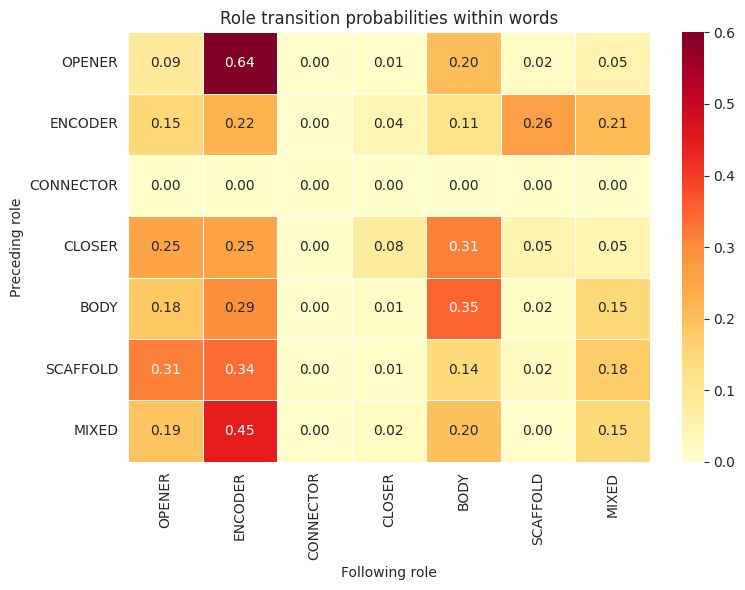


Key transitions (> 20%):
  OPENER → ENCODER: 63.5% (22,274 times)
  OPENER → BODY: 20.3% (7,130 times)
  ENCODER → ENCODER: 22.2% (12,219 times)
  ENCODER → SCAFFOLD: 26.5% (14,564 times)
  ENCODER → MIXED: 20.8% (11,459 times)
  CLOSER → OPENER: 24.9% (226 times)
  CLOSER → ENCODER: 25.5% (231 times)
  CLOSER → BODY: 31.4% (285 times)
  BODY → ENCODER: 29.5% (1,565 times)
  BODY → BODY: 34.8% (1,844 times)
  SCAFFOLD → OPENER: 31.4% (2,105 times)
  SCAFFOLD → ENCODER: 33.9% (2,268 times)
  MIXED → ENCODER: 44.5% (6,358 times)


In [24]:
# Cell 3: Role bigram transition matrix — which role follows which?

ROLES = ['OPENER', 'ENCODER', 'CONNECTOR', 'CLOSER', 'BODY', 'SCAFFOLD', 'MIXED']
role_idx = {r: i for i, r in enumerate(ROLES)}
n_roles = len(ROLES)

# Count role bigrams within words
bigram_counts = np.zeros((n_roles, n_roles))
for rs in role_sequences_clean:
    for i in range(len(rs) - 1):
        r1, r2 = rs[i], rs[i+1]
        if r1 in role_idx and r2 in role_idx:
            bigram_counts[role_idx[r1], role_idx[r2]] += 1

# Normalize to transition probabilities
row_sums = bigram_counts.sum(axis=1, keepdims=True)
row_sums[row_sums == 0] = 1
bigram_probs = bigram_counts / row_sums

# Display
df_bigram = pd.DataFrame(bigram_probs, index=ROLES, columns=ROLES).round(3)
print('Role transition probabilities (row → column):')
print(df_bigram.to_string())

# Heatmap
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(bigram_probs, annot=True, fmt='.2f', cmap='YlOrRd',
            xticklabels=ROLES, yticklabels=ROLES, ax=ax,
            vmin=0, vmax=0.6, linewidths=0.5)
ax.set_xlabel('Following role')
ax.set_ylabel('Preceding role')
ax.set_title('Role transition probabilities within words')
plt.tight_layout()
plt.show()

# Key transitions
print('\nKey transitions (> 20%):')
for i, r1 in enumerate(ROLES):
    for j, r2 in enumerate(ROLES):
        if bigram_probs[i, j] > 0.20:
            print(f'  {r1} → {r2}: {bigram_probs[i,j]:.1%} ({int(bigram_counts[i,j]):,} times)')

In [25]:
# Cell 3b: First and last role in words — are OPENERS really first and CLOSERS really last?

first_roles = Counter(rs[0] for rs in role_sequences_clean if len(rs) >= 2)
last_roles = Counter(rs[-1] for rs in role_sequences_clean if len(rs) >= 2)

print('Role at FIRST position of multi-glyph words:')
total_multi = sum(first_roles.values())
for r in ROLES:
    pct = first_roles.get(r, 0) / total_multi
    print(f'  {r:<12} {first_roles.get(r,0):>6,} ({pct:>5.1%})')

print('\nRole at LAST position of multi-glyph words:')
for r in ROLES:
    pct = last_roles.get(r, 0) / total_multi
    print(f'  {r:<12} {last_roles.get(r,0):>6,} ({pct:>5.1%})')

Role at FIRST position of multi-glyph words:
  OPENER       19,322 (54.6%)
  ENCODER      11,374 (32.1%)
  CONNECTOR         0 ( 0.0%)
  CLOSER           85 ( 0.2%)
  BODY          1,989 ( 5.6%)
  SCAFFOLD      1,588 ( 4.5%)
  MIXED         1,038 ( 2.9%)

Role at LAST position of multi-glyph words:
  OPENER        1,622 ( 4.6%)
  ENCODER       1,274 ( 3.6%)
  CONNECTOR         0 ( 0.0%)
  CLOSER        2,150 ( 6.1%)
  BODY         15,912 (45.0%)
  SCAFFOLD     10,368 (29.3%)
  MIXED         4,070 (11.5%)


---
## 2. Section classification from glyph frequency profiles

In [26]:
# Cell 4: Build per-folio glyph frequency vectors and classify by nearest section centroid

from sklearn.metrics.pairwise import cosine_similarity

# Build folio-level glyph frequency vectors
core_glyph_list = sorted(df_core['glyph'].tolist())
folio_vecs = defaultdict(lambda: np.zeros(len(core_glyph_list)))
folio_sections = {}
glyph_to_idx = {g: i for i, g in enumerate(core_glyph_list)}

for rec in records:
    if rec['section'] not in SECTIONS:
        continue
    f = rec['folio']
    folio_sections[f] = rec['section']
    for g in rec['glyphs']:
        if g in glyph_to_idx:
            folio_vecs[f][glyph_to_idx[g]] += 1

# Normalize to frequencies
for f in folio_vecs:
    s = folio_vecs[f].sum()
    if s > 0:
        folio_vecs[f] /= s

# Section centroids
section_centroids = {}
for sec in SECTIONS:
    folios_in_sec = [f for f, s in folio_sections.items() if s == sec]
    if folios_in_sec:
        section_centroids[sec] = np.mean([folio_vecs[f] for f in folios_in_sec], axis=0)

# Leave-one-out classification
correct = 0
total = 0
confusion = defaultdict(lambda: Counter())

for f, true_sec in folio_sections.items():
    if true_sec not in SECTIONS:
        continue
    vec = folio_vecs[f].reshape(1, -1)
    if vec.sum() == 0:
        continue
    # Compute cosine similarity to each section centroid (excluding this folio)
    best_sec, best_sim = None, -1
    for sec in SECTIONS:
        folios_in = [ff for ff, ss in folio_sections.items() if ss == sec and ff != f]
        if not folios_in:
            continue
        centroid = np.mean([folio_vecs[ff] for ff in folios_in], axis=0).reshape(1, -1)
        sim = cosine_similarity(vec, centroid)[0, 0]
        if sim > best_sim:
            best_sim = sim
            best_sec = sec
    confusion[true_sec][best_sec] += 1
    if best_sec == true_sec:
        correct += 1
    total += 1

accuracy = correct / total
print(f'Leave-one-out folio classification accuracy: {correct}/{total} = {accuracy:.1%}')
print(f'Chance level (largest class): {max(Counter(folio_sections.values()).values())/total:.1%}')

# Confusion matrix
print(f'\nConfusion matrix:')
print(f'{"":>10}', end='')
for sec in SECTIONS:
    print(f'{sec:>8}', end='')
print()
for true_sec in SECTIONS:
    print(f'{true_sec:>10}', end='')
    for pred_sec in SECTIONS:
        print(f'{confusion[true_sec][pred_sec]:>8}', end='')
    print()

Leave-one-out folio classification accuracy: 150/226 = 66.4%
Chance level (largest class): 48.7%

Confusion matrix:
            herbal   astro  zodiac     bio  pharma  recipe
    herbal      75       6       0       8      11      10
     astro       0       5       1       4       1       1
    zodiac       2       3      14       1       0       2
       bio       0       0       0      20       0       0
    pharma       0       1       0       0       5       0
    recipe       4       6       1       6       8      31


/tmp/ipykernel_76047/1040043433.py:10: UserWarning: 'where' used without 'out', expect unitialized memory in output. If this is intentional, use out=None.
  cm_norm = np.divide(cm, row_totals, where=row_totals != 0)


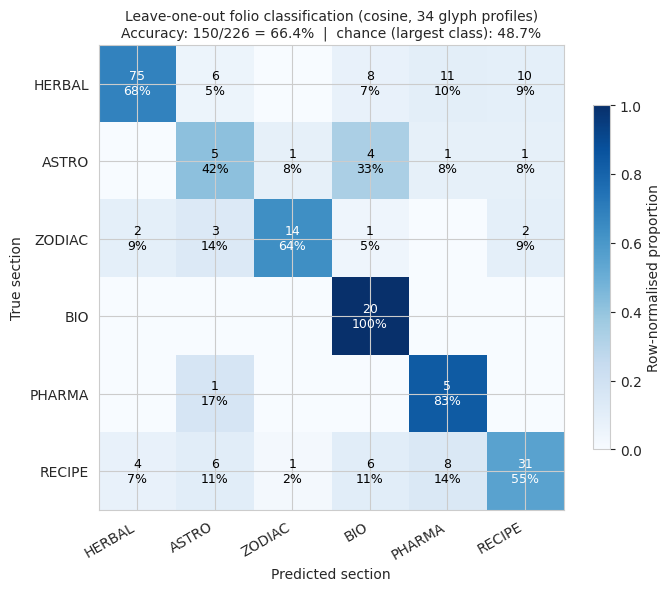

Saved: folio_section_confusion.png


In [27]:
# Cell 4b: Confusion matrix heatmap for folio classification
# Illustrates 66.4% accuracy (vs 49% chance) and the perfect bio=20/20.

cm = np.zeros((len(SECTIONS), len(SECTIONS)), dtype=int)
for i, true_sec in enumerate(SECTIONS):
    for j, pred_sec in enumerate(SECTIONS):
        cm[i, j] = confusion[true_sec][pred_sec]

row_totals = cm.sum(axis=1, keepdims=True)
cm_norm = np.divide(cm, row_totals, where=row_totals != 0)

fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
ax.set_xticks(range(len(SECTIONS)))
ax.set_yticks(range(len(SECTIONS)))
ax.set_xticklabels([s.upper() for s in SECTIONS], rotation=30, ha='right')
ax.set_yticklabels([s.upper() for s in SECTIONS])
ax.set_xlabel('Predicted section')
ax.set_ylabel('True section')

for i in range(len(SECTIONS)):
    for j in range(len(SECTIONS)):
        count = cm[i, j]
        prop = cm_norm[i, j]
        if count == 0:
            continue
        color = 'white' if prop > 0.5 else 'black'
        ax.text(j, i, f'{count}\n{prop:.0%}', ha='center', va='center',
                color=color, fontsize=9)

n_total = cm.sum()
n_correct = np.trace(cm)
chance = max(row_totals.flatten()) / n_total
ax.set_title(f'Leave-one-out folio classification (cosine, 34 glyph profiles)\n'
             f'Accuracy: {n_correct}/{n_total} = {n_correct/n_total:.1%}  |  '
             f'chance (largest class): {chance:.1%}',
             fontsize=10)
cbar = plt.colorbar(im, ax=ax, shrink=0.7)
cbar.set_label('Row-normalised proportion')
plt.tight_layout()
plt.savefig('folio_section_confusion.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: folio_section_confusion.png')


---
## 3. Glyph pair compatibility table

In [28]:
# Cell 5: Adjacent glyph pairs within words — which pairs are over/under-represented?

# Count adjacent pairs
pair_counts = Counter()
for word in palabras:
    for i in range(len(word) - 1):
        g1, g2 = word[i], word[i+1]
        if g1 in GLYPH_ROLE and g2 in GLYPH_ROLE:
            pair_counts[(g1, g2)] += 1

# Expected frequency under independence (marginal product)
glyph_freq = Counter()
total_bigrams = 0
for word in palabras:
    for i in range(len(word) - 1):
        g1, g2 = word[i], word[i+1]
        if g1 in GLYPH_ROLE and g2 in GLYPH_ROLE:
            glyph_freq[g1] += 1
            glyph_freq[g2] += 1
            total_bigrams += 1

# Top 30 most frequent pairs with enrichment
print(f'Total adjacent bigrams (core glyphs): {total_bigrams:,}')
print(f'\nTop 30 glyph pairs by observed/expected ratio:')
print(f'{"Pair":<12} {"Roles":<25} {"Obs":>7} {"Exp":>9} {"O/E":>6}')
print('-' * 65)

pair_enrichments = []
for (g1, g2), obs in pair_counts.items():
    # Expected under independence
    f1 = glyph_freq[g1] / (2 * total_bigrams)  # approximate marginal
    f2 = glyph_freq[g2] / (2 * total_bigrams)
    exp = f1 * f2 * total_bigrams
    if exp > 0 and obs >= 10:
        oe = obs / exp
        pair_enrichments.append((g1, g2, obs, exp, oe))

pair_enrichments.sort(key=lambda x: -x[4])
for g1, g2, obs, exp, oe in pair_enrichments[:30]:
    r1, r2 = GLYPH_ROLE.get(g1, '?'), GLYPH_ROLE.get(g2, '?')
    print(f'{g1}→{g2:<8} {r1}→{r2:<20} {obs:>7,} {exp:>9.1f} {oe:>6.1f}x')

# Also show most avoided pairs (lowest O/E with sufficient expected)
print(f'\nTop 15 most AVOIDED pairs (low O/E, expected >= 50):')
avoided = [(g1,g2,obs,exp,oe) for g1,g2,obs,exp,oe in pair_enrichments if exp >= 50]
avoided.sort(key=lambda x: x[4])
for g1, g2, obs, exp, oe in avoided[:15]:
    r1, r2 = GLYPH_ROLE.get(g1, '?'), GLYPH_ROLE.get(g2, '?')
    print(f'{g1}→{g2:<8} {r1}→{r2:<20} {obs:>7,} {exp:>9.1f} {oe:>6.2f}x')

Total adjacent bigrams (core glyphs): 118,841

Top 30 glyph pairs by observed/expected ratio:
Pair         Roles                         Obs       Exp    O/E
-----------------------------------------------------------------
Z1→Z1       SCAFFOLD→SCAFFOLD                  52       0.1  738.1x
E1→B3       CLOSER→CLOSER                    52       0.8   66.7x
A3→F1       ENCODER→BODY                   1,673      99.9   16.7x
A3→G1       ENCODER→MIXED                  3,905     242.2   16.1x
A3→E2       ENCODER→CLOSER                   121       8.3   14.6x
A3→F3       ENCODER→CLOSER                   608      44.0   13.8x
A3→B3       ENCODER→CLOSER                   779      62.1   12.5x
A3→G3       ENCODER→CLOSER                   141      11.5   12.3x
M1→C2       CLOSER→OPENER                    63       5.3   11.8x
A3→H1       ENCODER→ENCODER                  121      10.5   11.6x
D1→A1       OPENER→ENCODER                5,292     467.4   11.3x
Aa→C1       OPENER→SCAFFOLD              

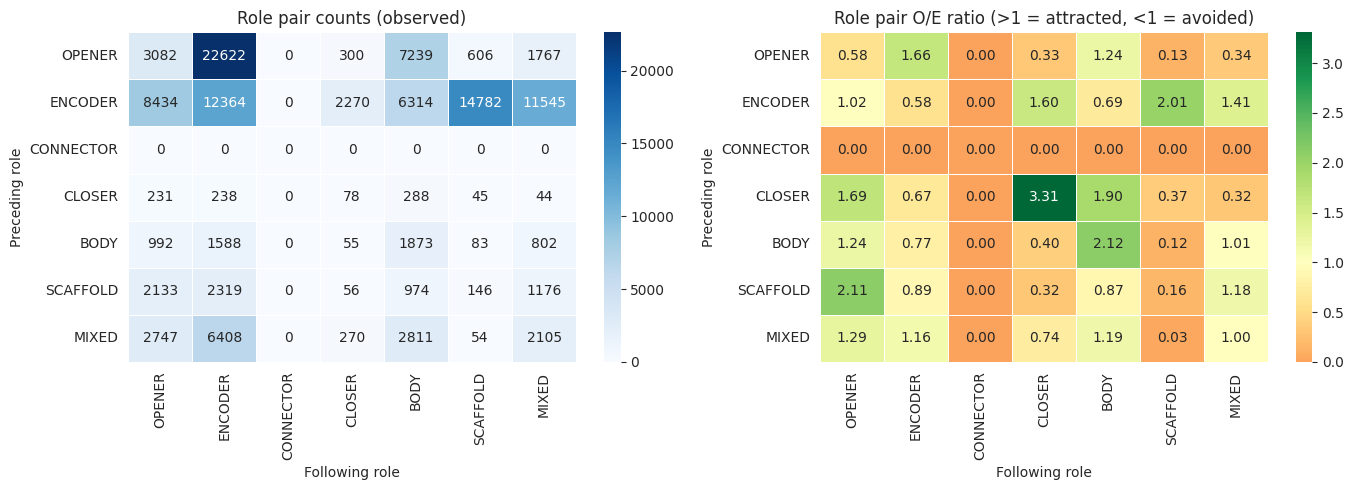

FORBIDDEN transitions (O/E < 0.3):
  OPENER → SCAFFOLD: O/E=0.13 (obs=606, exp=4710)
  BODY → SCAFFOLD: O/E=0.12 (obs=83, exp=713)
  SCAFFOLD → SCAFFOLD: O/E=0.16 (obs=146, exp=900)
  MIXED → SCAFFOLD: O/E=0.03 (obs=54, exp=1904)

STRONGLY ATTRACTED transitions (O/E > 2.0):
  ENCODER → SCAFFOLD: O/E=2.01 (obs=14782, exp=7367)
  CLOSER → CLOSER: O/E=3.31 (obs=78, exp=24)
  BODY → BODY: O/E=2.12 (obs=1873, exp=885)
  SCAFFOLD → OPENER: O/E=2.11 (obs=2133, exp=1009)


In [29]:
# Cell 5b: Role-level compatibility matrix (aggregated)

role_pair_obs = defaultdict(int)
role_pair_total = defaultdict(int)

for (g1, g2), cnt in pair_counts.items():
    r1, r2 = GLYPH_ROLE.get(g1), GLYPH_ROLE.get(g2)
    if r1 and r2:
        role_pair_obs[(r1, r2)] += cnt

# Build matrix
rp_matrix = np.zeros((n_roles, n_roles))
for (r1, r2), cnt in role_pair_obs.items():
    rp_matrix[role_idx[r1], role_idx[r2]] = cnt

# Expected under independence
row_totals = rp_matrix.sum(axis=1)
col_totals = rp_matrix.sum(axis=0)
grand_total = rp_matrix.sum()
rp_expected = np.outer(row_totals, col_totals) / grand_total
rp_expected[rp_expected == 0] = 1  # avoid div by zero
rp_oe = rp_matrix / rp_expected

# Heatmap of O/E
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(pd.DataFrame(rp_matrix.astype(int), index=ROLES, columns=ROLES),
            annot=True, fmt='d', cmap='Blues', ax=axes[0], linewidths=0.5)
axes[0].set_title('Role pair counts (observed)')

sns.heatmap(pd.DataFrame(rp_oe, index=ROLES, columns=ROLES).round(2),
            annot=True, fmt='.2f', cmap='RdYlGn', center=1.0, ax=axes[1], linewidths=0.5)
axes[1].set_title('Role pair O/E ratio (>1 = attracted, <1 = avoided)')

for ax in axes:
    ax.set_xlabel('Following role')
    ax.set_ylabel('Preceding role')

plt.tight_layout()
plt.show()

# Print forbidden/mandatory transitions
print('FORBIDDEN transitions (O/E < 0.3):')
for i, r1 in enumerate(ROLES):
    for j, r2 in enumerate(ROLES):
        if rp_oe[i,j] < 0.3 and rp_expected[i,j] > 50:
            print(f'  {r1} → {r2}: O/E={rp_oe[i,j]:.2f} (obs={int(rp_matrix[i,j])}, exp={rp_expected[i,j]:.0f})')

print('\nSTRONGLY ATTRACTED transitions (O/E > 2.0):')
for i, r1 in enumerate(ROLES):
    for j, r2 in enumerate(ROLES):
        if rp_oe[i,j] > 2.0 and rp_matrix[i,j] > 50:
            print(f'  {r1} → {r2}: O/E={rp_oe[i,j]:.2f} (obs={int(rp_matrix[i,j])}, exp={rp_expected[i,j]:.0f})')

---
## 4. Section marker dictionary

In [30]:
# Cell 6: For each section, find the glyphs most enriched relative to corpus average

# Section token totals
sec_totals = Counter()
sec_glyph = defaultdict(lambda: Counter())
for rec in records:
    sec = rec['section']
    if sec not in SECTIONS: continue
    for g in rec['glyphs']:
        sec_glyph[sec][g] += 1
        sec_totals[sec] += 1

corpus_total = sum(sec_totals.values())
corpus_glyph = Counter()
for sec in SECTIONS:
    for g, c in sec_glyph[sec].items():
        corpus_glyph[g] += c

# For each section, compute enrichment of each core glyph
print('SECTION MARKERS — glyphs most enriched in each section vs corpus average')
print('(enrichment = section_freq / corpus_freq)\n')

for sec in SECTIONS:
    enrichments = []
    for g in core_glyph_list:
        corpus_freq = corpus_glyph[g] / corpus_total if corpus_total else 0
        sec_freq = sec_glyph[sec].get(g, 0) / sec_totals[sec] if sec_totals[sec] else 0
        if corpus_freq > 0 and sec_freq > 0:
            enrich = sec_freq / corpus_freq
            enrichments.append((g, GLYPH_ROLE.get(g, '?'), sec_freq, corpus_freq, enrich))
    enrichments.sort(key=lambda x: -x[4])
    
    print(f'── {sec.upper()} (top 5 markers) ──')
    for g, role, sf, cf, en in enrichments[:5]:
        print(f'  {g:<6} ({role:<10}) sec={sf:.3%} corpus={cf:.3%} enrichment={en:.2f}x')
    
    # Also show most depleted
    enrichments.sort(key=lambda x: x[4])
    print(f'  --- most depleted ---')
    for g, role, sf, cf, en in enrichments[:3]:
        print(f'  {g:<6} ({role:<10}) sec={sf:.3%} corpus={cf:.3%} enrichment={en:.2f}x')
    print()

SECTION MARKERS — glyphs most enriched in each section vs corpus average
(enrichment = section_freq / corpus_freq)

── HERBAL (top 5 markers) ──
  E2     (CLOSER    ) sec=0.201% corpus=0.088% enrichment=2.29x
  U2     (OPENER    ) sec=1.216% corpus=0.577% enrichment=2.11x
  T1     (OPENER    ) sec=0.247% corpus=0.136% enrichment=1.81x
  B4     (CLOSER    ) sec=0.158% corpus=0.103% enrichment=1.53x
  K1     (OPENER    ) sec=9.733% corpus=7.075% enrichment=1.38x
  --- most depleted ---
  Z1     (SCAFFOLD  ) sec=0.008% corpus=0.068% enrichment=0.12x
  K2     (MIXED     ) sec=1.313% corpus=2.842% enrichment=0.46x
  Lb     (OPENER    ) sec=0.121% corpus=0.259% enrichment=0.47x

── ASTRO (top 5 markers) ──
  P2     (ENCODER   ) sec=0.643% corpus=0.263% enrichment=2.45x
  B4     (CLOSER    ) sec=0.247% corpus=0.103% enrichment=2.40x
  G3     (CLOSER    ) sec=0.260% corpus=0.110% enrichment=2.35x
  F3     (CLOSER    ) sec=0.791% corpus=0.394% enrichment=2.01x
  B3     (CLOSER    ) sec=1.113% c

Glyphs with section-heterogeneous distribution (p < 0.01): 33 / 34
Global chi-square: 6647.3, dof=165, p=0.00e+00


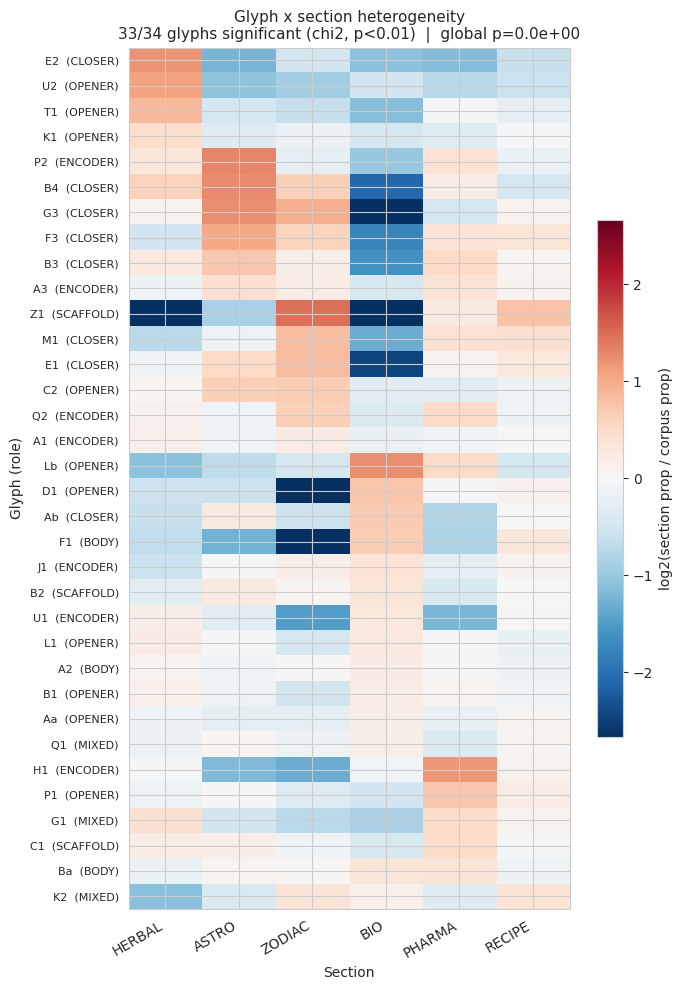

Saved: glyph_section_heatmap.png


In [31]:
# Cell 6b: Heatmap glyph x section (log2 enrichment) + chi-square test
# Illustrates that each section uses distinct glyph proportions.

from scipy.stats import chi2_contingency

# Build contingency table: rows = core glyphs, columns = sections
sec_order = list(SECTIONS)
glyphs_sorted = sorted(core_glyph_list)
M = np.array([[sec_glyph[s].get(g, 0) for s in sec_order] for g in glyphs_sorted], dtype=float)

# Global chi-square (overall heterogeneity)
chi2_global, p_global, dof_global, expected = chi2_contingency(M)

# Per-glyph chi-square: is THIS glyph's distribution across sections different from the corpus?
sec_tot = M.sum(axis=0)  # total tokens per section
per_glyph_p = []
for i, g in enumerate(glyphs_sorted):
    row = M[i]
    exp_row = row.sum() * sec_tot / sec_tot.sum()
    chi2_g = ((row - exp_row) ** 2 / exp_row).sum()
    dof_g = len(sec_order) - 1
    p_g = 1 - sp_stats.chi2.cdf(chi2_g, dof_g)
    per_glyph_p.append(p_g)
per_glyph_p = np.array(per_glyph_p)
n_sig = int((per_glyph_p < 0.01).sum())
print(f'Glyphs with section-heterogeneous distribution (p < 0.01): {n_sig} / {len(glyphs_sorted)}')
print(f'Global chi-square: {chi2_global:.1f}, dof={dof_global}, p={p_global:.2e}')

# Proportions per section (columns sum to 1) -> log2 enrichment vs corpus average
prop = M / M.sum(axis=0, keepdims=True)
corpus_prop = M.sum(axis=1) / M.sum()
with np.errstate(divide='ignore', invalid='ignore'):
    log2_enrich = np.log2(prop / corpus_prop[:, None])
log2_enrich = np.nan_to_num(log2_enrich, nan=0.0, posinf=0.0, neginf=0.0)

# Order glyphs by the section in which they are most enriched, then by enrichment magnitude
dominant_sec = log2_enrich.argmax(axis=1)
order = sorted(range(len(glyphs_sorted)),
               key=lambda i: (dominant_sec[i], -log2_enrich[i, dominant_sec[i]]))
log2_ordered = log2_enrich[order]
glyphs_ordered = [glyphs_sorted[i] for i in order]
roles_ordered = [GLYPH_ROLE.get(g, '?') for g in glyphs_ordered]

fig, ax = plt.subplots(figsize=(7, 10))
vmax = np.percentile(np.abs(log2_ordered), 98)
im = ax.imshow(log2_ordered, aspect='auto', cmap='RdBu_r', vmin=-vmax, vmax=vmax)
ax.set_xticks(range(len(sec_order)))
ax.set_xticklabels([s.upper() for s in sec_order], rotation=30, ha='right')
ax.set_yticks(range(len(glyphs_ordered)))
ax.set_yticklabels([f'{g}  ({r})' for g, r in zip(glyphs_ordered, roles_ordered)], fontsize=8)
ax.set_xlabel('Section')
ax.set_ylabel('Glyph (role)')
ax.set_title(f'Glyph x section heterogeneity\n'
             f'{n_sig}/{len(glyphs_sorted)} glyphs significant (chi2, p<0.01)  |  '
             f'global p={p_global:.1e}',
             fontsize=11)
cbar = plt.colorbar(im, ax=ax, shrink=0.6)
cbar.set_label('log2(section prop / corpus prop)')
plt.tight_layout()
plt.savefig('glyph_section_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print('Saved: glyph_section_heatmap.png')


---
## 5. Word length distribution by section

Section      Words  Mean len  Median    Std  1-glyph%  5+glyph%
------------------------------------------------------------
herbal       9,167      4.06     4.0   1.74      2.8%     33.8%
astro        1,964      4.12     4.0   1.76      9.6%     41.5%
zodiac       2,465      4.54     4.0   1.68      1.9%     49.1%
bio          6,768      4.27     4.0   1.46      1.6%     42.9%
pharma       1,819      4.15     4.0   1.45      0.8%     39.9%
recipe      14,385      4.31     4.0   1.55      1.8%     43.1%

Kruskal-Wallis: H=394.2, p=5.20e-83
SIGNIFICANT: word length differs across sections


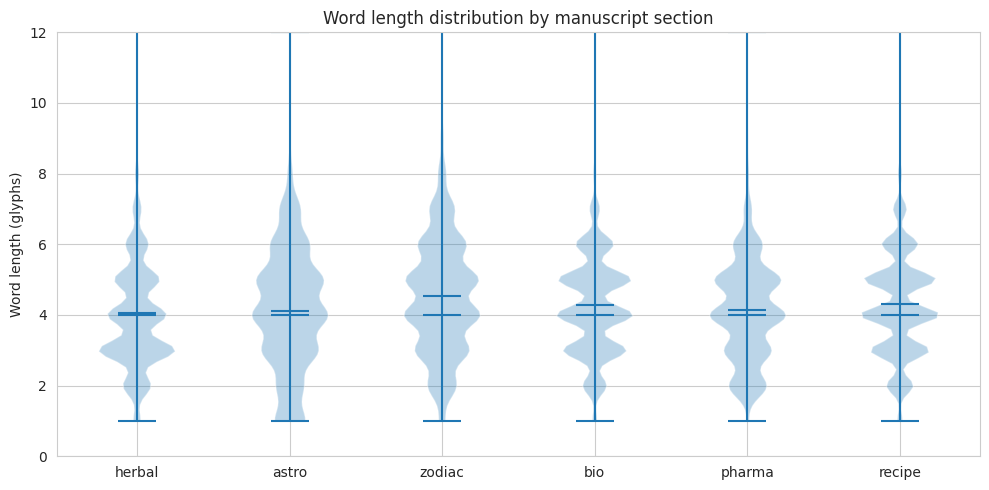


Distinct roles per word by section:
Section      Mean  Median
herbal       2.95     3.0
astro        2.90     3.0
zodiac       3.01     3.0
bio          3.15     3.0
pharma       2.94     3.0
recipe       3.05     3.0


In [32]:
# Cell 7: Word length (in glyphs) per section

sec_lengths = defaultdict(list)
for rec in records:
    sec = rec['section']
    if sec not in SECTIONS: continue
    sec_lengths[sec].append(len(rec['glyphs']))

print(f'{"Section":<10} {"Words":>7} {"Mean len":>9} {"Median":>7} {"Std":>6} {"1-glyph%":>9} {"5+glyph%":>9}')
print('-' * 60)
for sec in SECTIONS:
    lens = sec_lengths[sec]
    arr = np.array(lens)
    pct_1 = np.mean(arr == 1)
    pct_5 = np.mean(arr >= 5)
    print(f'{sec:<10} {len(lens):>7,} {arr.mean():>9.2f} {np.median(arr):>7.1f} {arr.std():>6.2f} {pct_1:>9.1%} {pct_5:>9.1%}')

# Kruskal-Wallis
groups = [np.array(sec_lengths[s]) for s in SECTIONS]
H, p = sp_stats.kruskal(*groups)
print(f'\nKruskal-Wallis: H={H:.1f}, p={p:.2e}')
print(f'{"SIGNIFICANT" if p < 0.01 else "NOT significant"}: word length differs across sections')

# Violin plot
fig, ax = plt.subplots(figsize=(10, 5))
data = [sec_lengths[s] for s in SECTIONS]
parts = ax.violinplot(data, positions=range(len(SECTIONS)), showmeans=True, showmedians=True)
ax.set_xticks(range(len(SECTIONS)))
ax.set_xticklabels(SECTIONS)
ax.set_ylabel('Word length (glyphs)')
ax.set_title('Word length distribution by manuscript section')
ax.set_ylim(0, 12)
plt.tight_layout()
plt.show()

# Role sequence length by section
sec_role_lens = defaultdict(list)
for rec in records:
    sec = rec['section']
    if sec not in SECTIONS: continue
    roles = word_to_roles(rec['glyphs'])
    n_distinct_roles = len(set(r for r in roles if r != '?'))
    sec_role_lens[sec].append(n_distinct_roles)

print(f'\nDistinct roles per word by section:')
print(f'{"Section":<10} {"Mean":>6} {"Median":>7}')
for sec in SECTIONS:
    arr = np.array(sec_role_lens[sec])
    print(f'{sec:<10} {arr.mean():>6.2f} {np.median(arr):>7.1f}')

In [33]:
# Cell 8: Final consolidated conclusions

print('='*80)
print('CONSOLIDATED CONCLUSIONS — Notebook 76')
print('='*80)

print('''
This notebook tested five predictions of the combinatorial code model
using the role classification established in notebook 75.

Results are printed above in each section. See the individual cells
for detailed tables, heatmaps, and statistical tests.

Key dependencies:
  - Corpus: corpus/voynich_sta.txt (STA1 2.0)
  - SilPart pipeline: TP-P20 segmentation from nb36
  - Role classification: from nb75
  - Section assignments: standard Voynich codicological sections
''')

CONSOLIDATED CONCLUSIONS — Notebook 76

This notebook tested five predictions of the combinatorial code model
using the role classification established in notebook 75.

Results are printed above in each section. See the individual cells
for detailed tables, heatmaps, and statistical tests.

Key dependencies:
  - Corpus: corpus/voynich_sta.txt (STA1 2.0)
  - SilPart pipeline: TP-P20 segmentation from nb36
  - Role classification: from nb75
  - Section assignments: standard Voynich codicological sections

